## Massachusetts Senate Voting Alignment Behavior Analysis

In [77]:
import pandas as pd 

In [ ]:
df = pd.read_csv("all_sessions_senate_final.csv")
df2 = df.copy()
print(df.columns)
df.head()

Index(['GeneralCourtNumber', 'MemberCode', 'Name', 'Branch', 'BillNumber',
       'RollCallNumber', 'QuestionMotion', 'Vote', 'Party', 'District',
       'LeadershipPosition', 'EmailAddress', 'PhoneNumber', 'RoomNumber',
       'MemberUrl', 'CommitteeName'],
      dtype='object')


,GeneralCourtNumber,MemberCode,Name,Branch,BillNumber,RollCallNumber,QuestionMotion,Vote,Party,District,LeadershipPosition,EmailAddress,PhoneNumber,RoomNumber,MemberUrl,CommitteeName
0,186,AWP0,Anthony W. Petruccelli,Senate,H4470,190,NaN,Yea,NaN,First Suffolk and Middlesex,NaN,NaN,NaN,NaN,http://malegislature.gov/api/GeneralCourts/186...,Education (J)
1,186,BAJ0,Brian A. Joyce,Senate,H4470,190,NaN,Yea,NaN,"Norfolk, Bristol and Plymouth",NaN,NaN,NaN,NaN,http://malegislature.gov/api/GeneralCourts/186...,Education (J)
2,186,BBD0,Benjamin B. Downing,Senate,H4470,190,NaN,Yea,NaN,"Berkshire, Hampshire, Franklin and Hampden",NaN,NaN,NaN,NaN,http://malegislature.gov/api/GeneralCourts/186...,Education (J)
3,186,BET0,Bruce E. Tarr,Senate,H4470,190,NaN,Yea,NaN,First Essex and Middlesex,NaN,NaN,NaN,NaN,http://malegislature.gov/api/GeneralCourts/186...,Education (J)
4,186,CSC0,Cynthia S. Creem,Senate,H4470,190,NaN,Yea,NaN,First Middlesex and Norfolk,NaN,NaN,NaN,NaN,http://malegislature.gov/api/GeneralCourts/186...,Education (J)


### 1. Member Alignment with Majority Leader

In [ ]:
df["Vote"] = df["Vote"].str.strip()


#Identify the majority leader for each session
majority_leaders = (
    df[df["LeadershipPosition"].str.contains("Majority Leader", na=True)]
      .groupby("GeneralCourtNumber")
      .agg({"MemberCode": "first"})
      .reset_index()
      .rename(columns={"MemberCode": "MajorityLeaderCode"})
)

#Determine whether each person aligns with the majority party leader.
df_leader_vote = df.merge(
    majority_leaders,
    on="GeneralCourtNumber",
    how="left"
)

# Get leader's vote choice for each roll call
leader_vote_map = (
    df_leader_vote.groupby(["GeneralCourtNumber", "RollCallNumber", "MajorityLeaderCode"])
    .agg(MajorityLeaderVote=("Vote", "first"))
    .reset_index()
)

# Merge leader vote information back to main data
df = df.merge(
    leader_vote_map,
    on=["GeneralCourtNumber", "RollCallNumber"],
    how="left"
)

# Mark whether each member aligns with leader (1=aligned, 0=not aligned)
df["AlignedWithLeader"] = (df["Vote"] == df["MajorityLeaderVote"]).astype(int)

# Calculate number of aligned members per party
party_alignment = (
    df.groupby(["GeneralCourtNumber", "RollCallNumber", "Party"])
    .agg(PartyAligned=("AlignedWithLeader", "sum"))
    .reset_index()
)

# Convert party alignment data to wide format (one column per party)
party_pivot = party_alignment.pivot_table(
    index=["GeneralCourtNumber", "RollCallNumber"],
    columns="Party",
    values="PartyAligned",
    fill_value=0
).reset_index()

party_pivot.columns = ["GeneralCourtNumber", "RollCallNumber", "PartyAligned_D", "PartyAligned_R"]

# Aggregate statistics by roll call
rollcall_summary = (
    df.groupby(["GeneralCourtNumber", "RollCallNumber", "BillNumber"])
    .agg(
        TotalVotes=("Vote", "count"),
        YeaCount=("Vote", lambda x: (x == "Yea").sum()),
        NayCount=("Vote", lambda x: (x == "Nay").sum()),
        AbsentCount=("Vote", lambda x: (x == "Absent").sum()),
        MajorityLeaderCode=("MajorityLeaderCode", "first"),
        MajorityLeaderVote=("MajorityLeaderVote", "first"),
        AlignedWithLeaderCount=("AlignedWithLeader", "sum"),
    )
).reset_index()
# Calculate overall alignment rate with leader
rollcall_summary["AlignmentRate"] = (
    rollcall_summary["AlignedWithLeaderCount"] / rollcall_summary["TotalVotes"]
)

#Determine if vote is unanimous
def unanimous_vote(row):
    if row["YeaCount"] == row["TotalVotes"]:
        return True, "Yea"
    if row["NayCount"] == row["TotalVotes"]:
        return True, "Nay"
    return False, None

unanimous_results = rollcall_summary.apply(
    lambda r: pd.Series(unanimous_vote(r), index=["IsUnanimous", "UnanimityVoteType"]),
    axis=1
)

rollcall_summary = pd.concat([rollcall_summary, unanimous_results], axis=1)
# Merge party alignment data
rollcall_summary = rollcall_summary.merge(
    party_pivot,
    on=["GeneralCourtNumber", "RollCallNumber"],
    how="left"
)

# Fill missing party data with 0
rollcall_summary["PartyAligned_D"] = rollcall_summary["PartyAligned_D"].fillna(0).astype(int)
rollcall_summary["PartyAligned_R"] = rollcall_summary["PartyAligned_R"].fillna(0).astype(int)



In [84]:
rollcall_summary.head()

,GeneralCourtNumber,RollCallNumber,BillNumber,TotalVotes,YeaCount,NayCount,AbsentCount,MajorityLeaderCode,MajorityLeaderVote,AlignedWithLeaderCount,AlignmentRate,IsUnanimous,UnanimityVoteType,PartyAligned_D,PartyAligned_R
0,186,190,H4470,38,35,0,3,AWP0,Yea,35,0.921053,False,None,1,0
1,186,191,H4475,38,33,3,2,AWP0,Yea,33,0.868421,False,None,1,0
2,186,192,S2290,38,17,19,2,AWP0,Nay,19,0.500000,False,None,0,0
3,186,287,S4,39,9,28,2,AWP0,Nay,28,0.717949,False,None,1,0
4,186,288,H4601,40,32,6,2,AWP0,Yea,32,0.800000,False,None,0,0


In [87]:
rollcall_summary.describe()
rollcall_summary["IsUnanimous"].value_counts()

IsUnanimous
False    1877
True      950
Name: count, dtype: int64

In [88]:
rollcall_summary.to_csv("senate_rollcall_alignment_summary.csv", index=False)

### 2. Member Voting Similarity Analysis
Using cosine similarity to calculate voting behavior consistency between every pair of members

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
import matplotlib.pyplot as plt

# Convert votes to numeric values
vote_map = {"Yea": 1, "Nay": -1, "Absent": 0}
df["VoteNumeric"] = df["Vote"].map(vote_map)

sessions = df["GeneralCourtNumber"].unique()

similarity_results = {}

for session in sorted(sessions):
    print(f"Processing session {session} ...")
    df_session = df[df["GeneralCourtNumber"] == session].copy()
    
    pivot = df_session.pivot_table(
        index="Name",
        columns="RollCallNumber",
        values="VoteNumeric"
    )
    
    pivot = pivot.dropna(thresh=5)
    
    sim_matrix = pd.DataFrame(
        cosine_similarity(pivot.fillna(0)),
        index=pivot.index,
        columns=pivot.index
    )
    similarity_results[session] = sim_matrix

similarity_results[194].head()
    

Processing session 186 ...
Processing session 188 ...
Processing session 189 ...
Processing session 190 ...
Processing session 191 ...
Processing session 192 ...
Processing session 193 ...
Processing session 194 ...


Name,Adam Gómez,Barry R. Finegold,Brendan P. Crighton,Bruce E. Tarr,Cindy F. Friedman,Cynthia Stone Creem,Dylan A. Fernandes,Edward J. Kennedy,Jacob R. Oliveira,James B. Eldridge,...,Paul R. Feeney,Paul W. Mark,Pavel M. Payano,Peter J. Durant,Rebecca L. Rausch,Robyn K. Kennedy,Ryan C. Fattman,Sal N. DiDomenico,"William J. Driscoll, Jr.",William N. Brownsberger
Name,,,,,,,,,,,,,,,,,,,,,
Adam Gómez,1.000000,0.952394,0.973559,0.317465,0.973559,0.973559,0.952394,0.801310,0.973559,0.952394,...,0.952394,0.973559,0.973559,0.275136,0.910066,0.973559,0.105822,0.973559,0.994723,0.973559
Barry R. Finegold,0.952394,1.000000,0.978947,0.305263,0.978947,0.978947,0.957895,0.809344,0.978947,0.915789,...,1.000000,0.978947,0.978947,0.263158,0.915789,0.978947,0.094737,0.978947,0.957895,0.978947
Brendan P. Crighton,0.973559,0.978947,1.000000,0.284211,1.000000,1.000000,0.978947,0.833870,1.000000,0.936842,...,0.978947,1.000000,1.000000,0.242105,0.936842,1.000000,0.073684,1.000000,0.978947,1.000000
Bruce E. Tarr,0.317465,0.305263,0.284211,1.000000,0.284211,0.284211,0.305263,0.147153,0.284211,0.347368,...,0.305263,0.284211,0.284211,0.915789,0.347368,0.284211,0.789474,0.284211,0.305263,0.284211
Cindy F. Friedman,0.973559,0.978947,1.000000,0.284211,1.000000,1.000000,0.978947,0.833870,1.000000,0.936842,...,0.978947,1.000000,1.000000,0.242105,0.936842,1.000000,0.073684,1.000000,0.978947,1.000000


In [51]:
similarity_results[190].head()

Name,Adam G. Hinds,Anne M. Gobi,Barbara A. L'Italien,Brendan P. Crighton,Bruce E. Tarr,Cindy F. Friedman,Cynthia Stone Creem,Dean A. Tran,"Donald F. Humason, Jr.",Eileen M. Donoghue,...,Paul R. Feeney,Richard J. Ross,Ryan C. Fattman,Sal N. DiDomenico,Sonia Chang-Diaz,Stanley C. Rosenberg,Thomas M. McGee,Viriato M. deMacedo,Walter F. Timilty,William N. Brownsberger
Name,,,,,,,,,,,,,,,,,,,,,
Adam G. Hinds,1.000000,0.893204,0.945796,0.639053,0.287986,0.905925,0.956602,0.501105,0.247132,0.714384,...,0.741951,0.393248,0.125442,0.984099,0.547353,0.468061,0.724485,0.193608,0.900265,0.964603
Anne M. Gobi,0.893204,1.000000,0.872136,0.606161,0.395411,0.810842,0.858412,0.542824,0.354497,0.702315,...,0.718487,0.501349,0.225949,0.893204,0.458723,0.331879,0.639957,0.294593,0.936508,0.873566
Barbara A. L'Italien,0.945796,0.872136,1.000000,0.615909,0.309339,0.884992,0.935835,0.509540,0.271765,0.695803,...,0.728205,0.408237,0.152892,0.938685,0.516346,0.433000,0.702454,0.218052,0.882793,0.918976
Brendan P. Crighton,0.639053,0.606161,0.615909,1.000000,0.417946,0.648095,0.605607,0.712448,0.390637,0.055912,...,0.776966,0.456235,0.377500,0.649839,0.414931,0.195869,0.000000,0.401203,0.611549,0.629380
Bruce E. Tarr,0.287986,0.395411,0.309339,0.417946,1.000000,0.224594,0.276352,0.567040,0.808473,0.077849,...,0.351571,0.795394,0.757951,0.287986,0.316888,0.192509,0.011995,0.795748,0.374228,0.281416


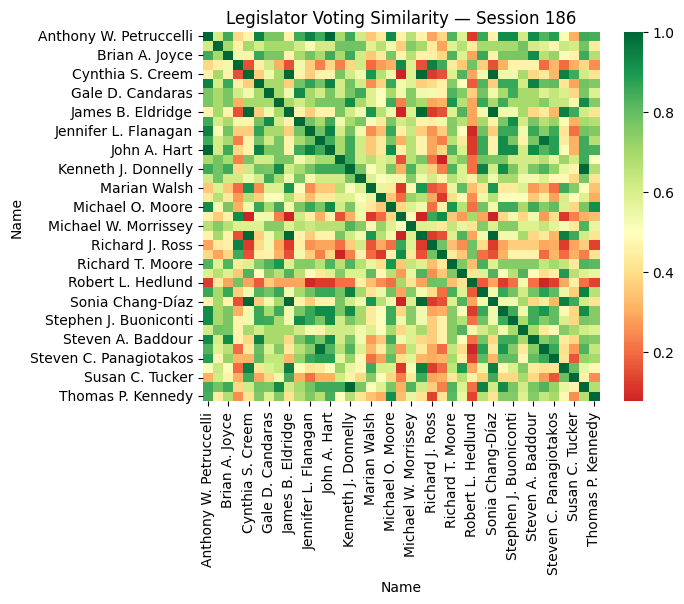

In [53]:
session = 186
sns.heatmap(similarity_results[session], cmap="RdYlGn", center=0.5)
plt.title(f"Legislator Voting Similarity — Session {session}")
plt.show()

Generate ALL pairwise combinations (including low similarity pairs)

In [ ]:
session_numbers = [194, 193, 192, 191, 190, 189, 188, 186]

all_sessions_matches = []

for session in session_numbers:
    print(f"Processing session {session} ...")

    corr_matrix = similarity_results[session]
    df_info = df2[df2["GeneralCourtNumber"] == session][
        ["Name", "Party", "LeadershipPosition"]
    ].drop_duplicates(subset=["Name"])

    # Iterate through all member pairs (no filtering)
    for i in range(len(corr_matrix)):
        for j in range(len(corr_matrix)):
            if i != j:  # Exclude self-pairs
                member1 = corr_matrix.index[i]
                member2 = corr_matrix.columns[j]
                correlation = corr_matrix.iloc[i, j]

                # Get party and position for both members
                m1_info = df_info[df_info["Name"] == member1]
                m2_info = df_info[df_info["Name"] == member2]
                m1_party = m1_info["Party"].values[0] if not m1_info.empty else None
                m2_party = m2_info["Party"].values[0] if not m2_info.empty else None
                m1_pos = m1_info["LeadershipPosition"].values[0] if not m1_info.empty else None
                m2_pos = m2_info["LeadershipPosition"].values[0] if not m2_info.empty else None

                # Derived fields
                same_party = (m1_party == m2_party) if (m1_party and m2_party) else None
                any_leader = bool(m1_pos or m2_pos)
                both_leader = bool(m1_pos and m2_pos)
                cross_party_highsim = (m1_party != m2_party) and (correlation >= 0.9)

                all_sessions_matches.append({
                    "GeneralCourtNumber": session,
                    "Member1": member1,
                    "Member2": member2,
                    "Cordex": correlation,
                    "Member1Party": m1_party,
                    "Member2Party": m2_party,
                    "Member1Position": m1_pos,
                    "Member2Position": m2_pos,
                    "SameParty": same_party,
                    "AnyLeader": any_leader,
                    "BothLeaders": both_leader,
                    "CrossPartyHighSim": cross_party_highsim
                })

all_sessions_df = pd.DataFrame(all_sessions_matches)

print(all_sessions_df.head())
print("\nColumns:")
print(all_sessions_df.columns.tolist())


Processing session 194 ...
Processing session 193 ...
Processing session 192 ...
Processing session 191 ...
Processing session 190 ...
Processing session 189 ...
Processing session 188 ...
Processing session 186 ...
   GeneralCourtNumber     Member1              Member2    Cordex Member1Party  \
0                 194  Adam Gómez    Barry R. Finegold  0.952394     Democrat   
1                 194  Adam Gómez  Brendan P. Crighton  0.973559     Democrat   
2                 194  Adam Gómez        Bruce E. Tarr  0.317465     Democrat   
3                 194  Adam Gómez    Cindy F. Friedman  0.973559     Democrat   
4                 194  Adam Gómez  Cynthia Stone Creem  0.973559     Democrat   

  Member2Party Member1Position  Member2Position  SameParty  AnyLeader  \
0     Democrat             NaN              NaN       True       True   
1     Democrat             NaN              NaN       True       True   
2   Republican             NaN  Minority Leader      False       True   
3    

In [ ]:
print(all_sessions_df.shape)

all_sessions_df.to_csv("senate_member_corr.csv", index=False)
print("Saved to senate_member_corr.csv")

(13228, 12)
Saved to senate_member_corr.csv


Extract only highly similar pairs (similarity ≥ 0.99)

In [ ]:
session_numbers = [194, 193, 192,191,190,189,188,186] 
all_sessions_matches = []

for session in session_numbers:
    print(f"processing {session} session...")
    
    corr_matrix = similarity_results[session]
    
    for i in range(len(corr_matrix)):
        for j in range(i+1, len(corr_matrix)):
            if corr_matrix.iloc[i, j] >= 0.99:
                member1 = corr_matrix.index[i]
                member2 = corr_matrix.columns[j]
                correlation = corr_matrix.iloc[i, j]
                
                # Add bidirectional relationship A -> B
                all_sessions_matches.append({
                    'GeneralCourtNumber': session,
                    'Member1': member1,
                    'Member2': member2,
                    'Cordex': correlation
                })
                
                # Add reverse relationship B -> A
                all_sessions_matches.append({
                    'GeneralCourtNumber': session,
                    'Member1': member2,
                    'Member2': member1,
                    'Cordex': correlation
                })

all_sessions_df = pd.DataFrame(all_sessions_matches)

print("\nAll sessions voted unanimously in favor of the resolution.:")
print(all_sessions_df.head(20))

print(f"\nData Statistics:")
print(f"total records: {len(all_sessions_df)}")
print(f"Number of sessions included: {sorted(all_sessions_df['GeneralCourtNumber'].unique())}")

print("\nNumber of pairings per session:")
session_stats = all_sessions_df.groupby('GeneralCourtNumber').size() / 2  # 除以2因为是双向的
print(session_stats)



processing 194 session...
processing 193 session...
processing 192 session...
processing 191 session...
processing 190 session...
processing 189 session...
processing 188 session...
processing 186 session...

All sessions voted unanimously in favor of the resolution.:
    GeneralCourtNumber                   Member1                   Member2  \
0                  194                Adam Gómez  William J. Driscoll, Jr.   
1                  194  William J. Driscoll, Jr.                Adam Gómez   
2                  194         Barry R. Finegold            Paul R. Feeney   
3                  194            Paul R. Feeney         Barry R. Finegold   
4                  194       Brendan P. Crighton         Cindy F. Friedman   
5                  194         Cindy F. Friedman       Brendan P. Crighton   
6                  194       Brendan P. Crighton       Cynthia Stone Creem   
7                  194       Cynthia Stone Creem       Brendan P. Crighton   
8                  194       

In [ ]:
df2_unique = df2[['GeneralCourtNumber', 'Name', 'LeadershipPosition', 'Party']].drop_duplicates(
    subset=['GeneralCourtNumber', 'Name']
)

all_sessions_df = all_sessions_df.merge(
    df2_unique,
    left_on=['GeneralCourtNumber', 'Member1'],
    right_on=['GeneralCourtNumber', 'Name'],
    how='left'
) 

all_sessions_df = all_sessions_df.drop(columns=['Name'])
all_sessions_df = all_sessions_df.rename(columns={'LeadershipPosition': 'Member1Position', 'Party': 'Member1Party'})


all_sessions_df = all_sessions_df.merge(
    df2_unique,
    left_on=['GeneralCourtNumber', 'Member2'],
    right_on=['GeneralCourtNumber', 'Name'],
    how='left',
    suffixes=('', '_drop')
)

all_sessions_df = all_sessions_df.drop(columns=['Name'])
all_sessions_df = all_sessions_df.rename(columns={'LeadershipPosition': 'Member2Position', 'Party': 'Member2Party'})


print(all_sessions_df.head(10))

print("\ncol names:")
print(all_sessions_df.columns.tolist())

   GeneralCourtNumber                   Member1                   Member2  \
0                 194                Adam Gómez  William J. Driscoll, Jr.   
1                 194  William J. Driscoll, Jr.                Adam Gómez   
2                 194         Barry R. Finegold            Paul R. Feeney   
3                 194            Paul R. Feeney         Barry R. Finegold   
4                 194       Brendan P. Crighton         Cindy F. Friedman   
5                 194         Cindy F. Friedman       Brendan P. Crighton   
6                 194       Brendan P. Crighton       Cynthia Stone Creem   
7                 194       Cynthia Stone Creem       Brendan P. Crighton   
8                 194       Brendan P. Crighton         Jacob R. Oliveira   
9                 194         Jacob R. Oliveira       Brendan P. Crighton   

     Cordex  Member1Position Member1Party  Member2Position Member2Party  
0  0.994723              NaN     Democrat              NaN     Democrat  
1  0

In [73]:
all_sessions_df.to_csv("Senate_Legis_Vote_Corr.csv", index=False)

In [ ]:
#df2_unique.head(50)

,GeneralCourtNumber,Name,LeadershipPosition,Party
0,194,Adam Gómez,NaN,Democrat
95,194,Barry R. Finegold,NaN,Democrat
190,194,Brendan P. Crighton,NaN,Democrat
285,194,Bruce E. Tarr,Minority Leader,Republican
380,194,Cindy F. Friedman,NaN,Democrat
475,194,Cynthia Stone Creem,Majority Leader,Democrat
570,194,Dylan A. Fernandes,NaN,Democrat
665,194,Edward J. Kennedy,NaN,Democrat
735,194,Jacob R. Oliveira,NaN,Democrat
830,194,James B. Eldridge,NaN,Democrat


In [ ]:
#all_sessions_df.shape

(590, 8)